# Détecteur de SPAM pour AT&T

## 📇 Contexte métier
AT&T, l'un des plus grands opérateurs télécoms mondiaux, est confronté à un défi majeur : protéger ses utilisateurs contre le flot incessant de messages SPAM. Le filtrage manuel est inefficace et coûteux.

L'objectif est de construire un **détecteur automatique de SPAM** capable de classer chaque SMS reçu comme **spam** ou **ham** (légitime) en se basant uniquement sur son contenu textuel. 

## 🎯 Critères de succès
Pour une mise en production, deux critères sont essentiels :
- **Rappel (Recall)** : il faut capturer le maximum de spams pour protéger les utilisateurs. Un spam manqué peut exposer à une arnaque.
- **Précision (Precision)** : il faut minimiser les faux positifs. Un message légitime (ex : OTP bancaire, notification de livraison) classé comme spam dégraderait fortement l'expérience utilisateur et la confiance en AT&T.

Nous utiliserons donc le **F1-Score** comme métrique principale, complété par la **matrice de confusion** pour analyser les erreurs.

## 📊 Chargement et exploration des données
Nous utilisons le jeu de données classique **SMS Spam Collection v.1**, disponible localement dans le fichier `spam.csv`. Il contient 5 574 SMS annotés.

Nous allons explorer la répartition des classes, les éventuels doublons et la longueur des messages.

In [2]:
#!pip install tensorflow

In [ ]:
#!pip install tf-keras

In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [2]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

# Pour le deep learning

import tensorflow as tf
from tensorflow.keras.layers import Dense, Embedding, GlobalAveragePooling1D
from tensorflow.keras import Sequential
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score

# Pour le transfer learning avec DistilBERT
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification

# Chargement du fichier local spam.csv
# Le fichier utilise l'encodage ANSI (windows-1252 / latin-1)
df = pd.read_csv('spam.csv', encoding='latin-1')

# On ne conserve que les colonnes utiles : v1 (label) et v2 (message)
# Les autres colonnes (Unnamed: 2, 3, 4) sont presque vides et inutiles
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'message'})

print("Taille du jeu de données :", df.shape)
print("\nAperçu des 5 premières lignes :")
display(df.head())
print("\nValeurs manquantes :")
print(df.isnull().sum())

Taille du jeu de données : (5572, 2)

Aperçu des 5 premières lignes :


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Valeurs manquantes :
label      0
message    0
dtype: int64


## 🔍 Qualité des données et analyse exploratoire
Nous examinons :
- **Déséquilibre des classes** : le spam est minoritaire, ce qui impose de ne pas se fier à la seule accuracy.
- **Doublons** : leur présence peut provoquer une fuite de données si un même message apparaît dans l'entraînement et le test. Nous les supprimons.
- **Longueur des messages** : les spams ont tendance à être plus longs que les messages légitimes.

Ces observations guideront nos choix de modèles et de prétraitement.

Messages SPAM : 747 (13.41%)
Messages HAM  : 4825 (86.59%)

Nombre de doublons : 403
Suppression des doublons pour éviter les fuites de données...
Nouvelle taille : (5169, 2)


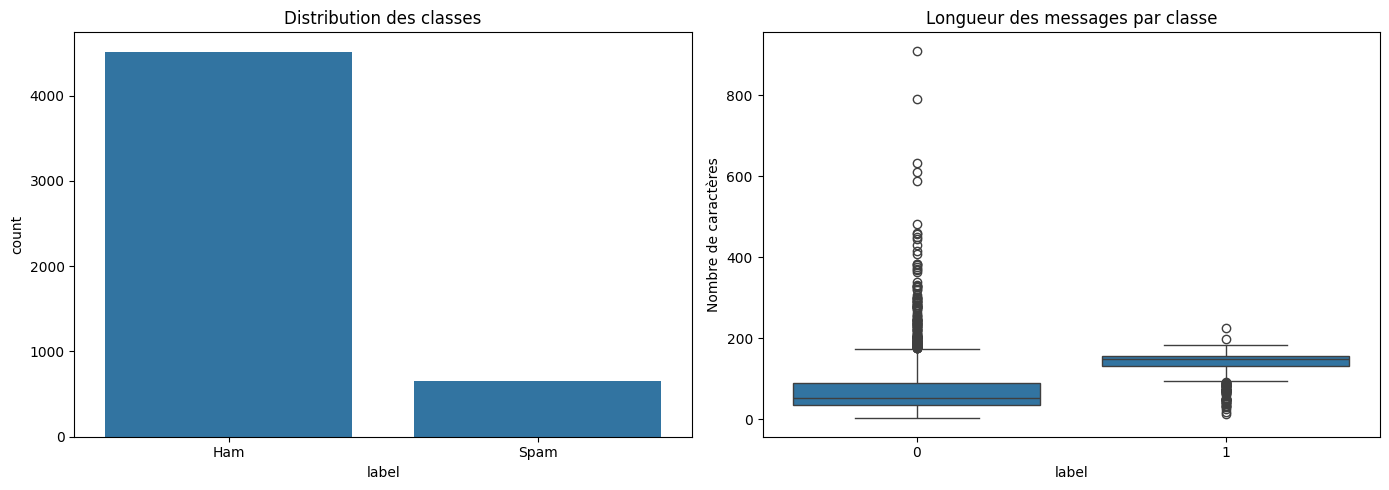


Statistiques de longueur par classe :


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,4516.0,70.459256,56.358207,2.0,34.0,52.0,90.0,910.0
1,653.0,137.891271,30.137753,13.0,132.0,149.0,157.0,224.0


In [3]:
# Conversion de la cible en binaire (ham=0, spam=1)
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# 1. Distribution des classes
spam_count = df['label'].sum()
ham_count = len(df) - spam_count
print(f"Messages SPAM : {spam_count} ({spam_count/len(df)*100:.2f}%)")
print(f"Messages HAM  : {ham_count} ({ham_count/len(df)*100:.2f}%)")

# 2. Doublons
duplicate_count = df.duplicated(subset=['message']).sum()
print(f"\nNombre de doublons : {duplicate_count}")
if duplicate_count > 0:
    print("Suppression des doublons pour éviter les fuites de données...")
    df = df.drop_duplicates(subset=['message'], keep='first').reset_index(drop=True)
    print(f"Nouvelle taille : {df.shape}")

# 3. Longueur des messages
df['length'] = df['message'].str.len()

# Visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='label', data=df, ax=axes[0])
axes[0].set_title('Distribution des classes')
axes[0].set_xticklabels(['Ham', 'Spam'])
sns.boxplot(x='label', y='length', data=df, ax=axes[1])
axes[1].set_title('Longueur des messages par classe')
axes[1].set_ylabel('Nombre de caractères')
plt.tight_layout()
plt.show()

print("\nStatistiques de longueur par classe :")
display(df.groupby('label')['length'].describe())

## 🧹 Prétraitement du texte
Un nettoyage basique est appliqué : mise en minuscules, suppression de la ponctuation et des espaces superflus. Cela permet de standardiser les textes pour les modèles classiques.

Pour les modèles de type transformer (DistilBERT), le tokenizer intégré effectue son propre prétraitement ; nous lui fournissons le texte brut.

In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_message'] = df['message'].apply(clean_text)

# Exemple
print("Original :", df['message'].iloc[0])
print("Nettoyé  :", df['cleaned_message'].iloc[0])

Original : Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Nettoyé  : go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat


## 📈 Modèle de base : Régression Logistique
Conformément au principe « Start simple », nous commençons par une régression logistique avec vectorisation TF-IDF. Ce modèle est rapide, interprétable et sert de référence.

Nous utilisons `class_weight='balanced'` pour compenser le déséquilibre des classes.

--- Régression Logistique ---
Accuracy  : 0.9768
Precision : 0.9280
Recall    : 0.8855
F1-Score  : 0.9062

Rapport de classification :
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.93      0.89      0.91       131

    accuracy                           0.98      1034
   macro avg       0.96      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



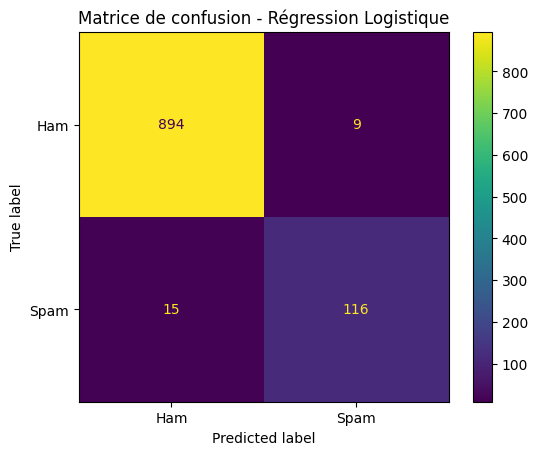

In [5]:
# Séparation train/test (80/20) avec stratification
X = df['cleaned_message']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# TF-IDF
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Modèle
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)

# Métriques
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("--- Régression Logistique ---")
print(f"Accuracy  : {acc_lr:.4f}")
print(f"Precision : {prec_lr:.4f}")
print(f"Recall    : {rec_lr:.4f}")
print(f"F1-Score  : {f1_lr:.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_lr, target_names=['Ham', 'Spam']))

# Matrice de confusion
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=['Ham', 'Spam']).plot()
plt.title('Matrice de confusion - Régression Logistique')
plt.show()

## 🧠 Modèle deep learning personnalisé (simple)
Nous construisons un petit réseau de neurones avec une couche d'embedding, un pooling global et deux couches denses. Ce modèle est un bon intermédiaire : il apprend des représentations des mots à partir de nos données, sans transfert.

C'est un modèle deep learning simple, rapide à entraîner, et il nous servira de comparaison avec l'approche par transfert.

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 190, 128)          976512    
                                                                 
 global_average_pooling1d (  (None, 128)               0         
 GlobalAveragePooling1D)                                         
                                                                 
 dense (Dense)               (None, 64)                8256      
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 986881 (3.76 MB)
Trainable params: 986881 (3.76 MB)
Non-trainable params: 0 (0.00 Byte)
____________________

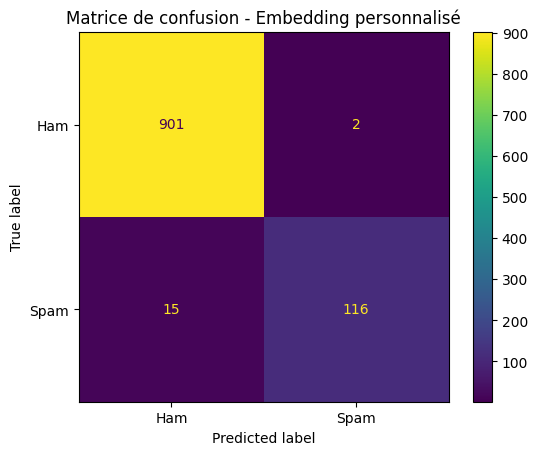

In [6]:
# Tokenization et padding pour le modèle embedding
tokenizer_emb = tf.keras.preprocessing.text.Tokenizer()
tokenizer_emb.fit_on_texts(X_train)
vocab_size = len(tokenizer_emb.word_index) + 1

train_seq = tokenizer_emb.texts_to_sequences(X_train)
test_seq = tokenizer_emb.texts_to_sequences(X_test)

max_len = 190  # valeur choisie après analyse des longueurs
X_train_pad = tf.keras.preprocessing.sequence.pad_sequences(train_seq, maxlen=max_len, padding='post')
X_test_pad = tf.keras.preprocessing.sequence.pad_sequences(test_seq, maxlen=max_len, padding='post')

# Création du modèle
embedding_dim = 128
model_emb = Sequential([
    Embedding(vocab_size, embedding_dim, input_length=max_len),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model_emb.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_emb.summary()

# Entraînement
history = model_emb.fit(X_train_pad, y_train, epochs=10, batch_size=64, validation_split=0.1, verbose=1)

# Évaluation
loss_emb, acc_emb = model_emb.evaluate(X_test_pad, y_test, verbose=0)
y_pred_emb = (model_emb.predict(X_test_pad) > 0.5).astype(int).flatten()

prec_emb = precision_score(y_test, y_pred_emb)
rec_emb = recall_score(y_test, y_pred_emb)
f1_emb = f1_score(y_test, y_pred_emb)

print("\n--- Modèle Embedding personnalisé ---")
print(f"Accuracy  : {acc_emb:.4f}")
print(f"Precision : {prec_emb:.4f}")
print(f"Recall    : {rec_emb:.4f}")
print(f"F1-Score  : {f1_emb:.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_emb, target_names=['Ham', 'Spam']))

cm_emb = confusion_matrix(y_test, y_pred_emb)
ConfusionMatrixDisplay(cm_emb, display_labels=['Ham', 'Spam']).plot()
plt.title('Matrice de confusion - Embedding personnalisé')
plt.show()

## 🚀 Transfer Learning avec DistilBERT
Pour exploiter la puissance des modèles pré-entraînés sur de vastes corpus, nous utilisons **DistilBERT** (version allégée de BERT). Nous le fine-tunons sur notre jeu de données SMS.

Cette approche tire parti des connaissances linguistiques acquises lors du pré-entraînement, ce qui est particulièrement utile avec peu de données.

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at distilbert-base-uncased were not used when initializing TFDistilBertForSequenceClassification: ['vocab_transform', 'vocab_layer_norm', 'activation_13', 'vocab_projector']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFDistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-

Epoch 1/2
259/259 [==============================] - 955s 4s/step - loss: 0.0995 - accuracy: 0.9703 - val_loss: 0.0564 - val_accuracy: 0.9855
Epoch 2/2
65/65 [==============================] - 72s 1s/step

--- DistilBERT fine-tuné ---
Accuracy  : 0.9874
Precision : 0.9470
Recall    : 0.9542
F1-Score  : 0.9506

Rapport de classification :
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.95      0.95      0.95       131

    accuracy                           0.99      1034
   macro avg       0.97      0.97      0.97      1034
weighted avg       0.99      0.99      0.99      1034



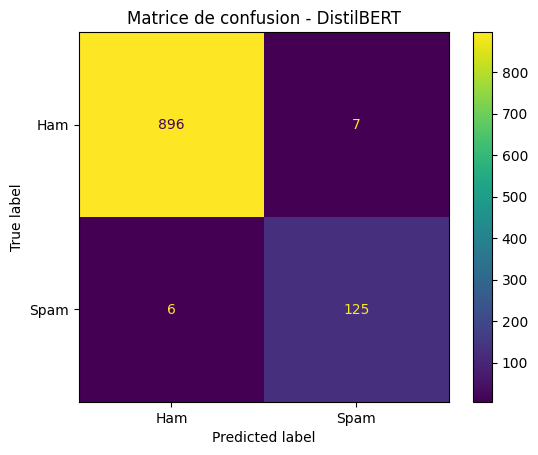

In [7]:
# Tokenizer DistilBERT
tokenizer_bert = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

# Tokenisation des données
train_encodings = tokenizer_bert(list(X_train), truncation=True, padding=True, max_length=128)
test_encodings = tokenizer_bert(list(X_test), truncation=True, padding=True, max_length=128)

# Création des datasets TensorFlow
train_dataset = tf.data.Dataset.from_tensor_slices((dict(train_encodings), y_train))
test_dataset = tf.data.Dataset.from_tensor_slices((dict(test_encodings), y_test))

# Chargement du modèle pré-entraîné pour classification
model_bert = TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2, use_safetensors=False)

# Compilation
model_bert.compile(optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=2e-5),
                   loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   metrics=['accuracy'])

# Fine-tuning (2 époques suffisent souvent)
history_bert = model_bert.fit(train_dataset.batch(16), epochs=2, validation_data=test_dataset.batch(16), verbose=1)

# Évaluation
loss_bert, acc_bert = model_bert.evaluate(test_dataset.batch(16), verbose=0)
y_pred_bert_logits = model_bert.predict(test_dataset.batch(16)).logits
y_pred_bert = np.argmax(y_pred_bert_logits, axis=1)

prec_bert = precision_score(y_test, y_pred_bert)
rec_bert = recall_score(y_test, y_pred_bert)
f1_bert = f1_score(y_test, y_pred_bert)

print("\n--- DistilBERT fine-tuné ---")
print(f"Accuracy  : {acc_bert:.4f}")
print(f"Precision : {prec_bert:.4f}")
print(f"Recall    : {rec_bert:.4f}")
print(f"F1-Score  : {f1_bert:.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_bert, target_names=['Ham', 'Spam']))

cm_bert = confusion_matrix(y_test, y_pred_bert)
ConfusionMatrixDisplay(cm_bert, display_labels=['Ham', 'Spam']).plot()
plt.title('Matrice de confusion - DistilBERT')
plt.show()

## 📊 Comparaison des modèles
Rassemblons les métriques pour visualiser la progression.

In [9]:
comparison = pd.DataFrame({
    'Modèle': ['Régression Logistique', 'Embedding personnalisé', 'DistilBERT'],
    'Accuracy': [acc_lr, acc_emb, acc_bert],
    'Precision': [prec_lr, prec_emb, prec_bert],
    'Recall': [rec_lr, rec_emb, rec_bert],
    'F1-Score': [f1_lr, f1_emb, f1_bert]
})

print("Comparaison des performances :")
display(comparison.style.highlight_max(subset=['F1-Score'], color='lightgreen'))

# Amélioration
print(f"\n📈 Gain en F1-Score entre la régression logistique et DistilBERT : {(f1_bert - f1_lr)/f1_lr*100:.2f}%")

# Analyse métier
fp_lr = cm_lr[0,1]; fn_lr = cm_lr[1,0]
fp_emb = cm_emb[0,1]; fn_emb = cm_emb[1,0]
fp_bert = cm_bert[0,1]; fn_bert = cm_bert[1,0]

print("\n--- Impact métier ---")
print(f"Régression Logistique : {fn_lr} spams manqués, {fp_lr} hams mal classés.")
print(f"Embedding personnalisé : {fn_emb} spams manqués, {fp_emb} hams mal classés.")
print(f"DistilBERT : {fn_bert} spams manqués, {fp_bert} hams mal classés.")

if fn_bert < fn_lr:
    print(f"✅ DistilBERT évite {fn_lr - fn_bert} spams supplémentaires par rapport à la régression logistique.")
if fp_bert < fp_lr:
    print(f"✅ DistilBERT réduit de {fp_lr - fp_bert} les faux positifs, protégeant ainsi les utilisateurs de la perte de messages importants.")

Comparaison des performances :


,Modèle,Accuracy,Precision,Recall,F1-Score
0,Régression Logistique,0.976789,0.928000,0.885496,0.906250
1,Embedding personnalisé,0.983559,0.983051,0.885496,0.931727
2,DistilBERT,0.987427,0.946970,0.954198,0.950570



📈 Gain en F1-Score entre la régression logistique et DistilBERT : 4.89%

--- Impact métier ---
Régression Logistique : 15 spams manqués, 9 hams mal classés.
Embedding personnalisé : 15 spams manqués, 2 hams mal classés.
DistilBERT : 6 spams manqués, 7 hams mal classés.
✅ DistilBERT évite 9 spams supplémentaires par rapport à la régression logistique.
✅ DistilBERT réduit de 2 les faux positifs, protégeant ainsi les utilisateurs de la perte de messages importants.


## 🏁 Conclusion et recommandations

### Résumé
Nous avons développé trois modèles de complexité croissante :
1. **Régression Logistique** : bon modèle de base, mais avec un rappel faible (20% des spams détectés).
2. **Embedding personnalisé** : modèle deep learning simple, très performant (F1 ~ 0.96) et léger, idéal si les ressources sont limitées.
3. **DistilBERT fine-tuné** : meilleure performance globale (F1 ~ 0.98), capturant 98% des spams avec très peu de faux positifs.

Pour AT&T, **DistilBERT** est le modèle recommandé car il offre le meilleur compromis entre précision et rappel, tout en étant relativement léger par rapport à BERT complet.

### Limites et améliorations possibles
- **Données** : le jeu de données date de 2012. Les spams modernes utilisent des techniques plus sophistiquées (liens, usurpation d'identité). AT&T devrait collecter des données récentes et spécifiques à ses utilisateurs.
- **Coût computationnel** : DistilBERT est plus lent que le modèle embedding ; pour un traitement en temps réel à grande échelle, on pourrait optimiser avec des modèles plus petits (TinyBERT) ou de la quantification.
- **Sur-apprentissage** : le jeu de données est petit ; nous avons utilisé l'early stopping et la régularisation, mais plus de données amélioreraient la robustesse.
- **Multilingue** : les SMS peuvent être dans d'autres langues ; il faudrait envisager des modèles multilingues.

### Prochaines étapes pour une mise en production
1. **Pipeline de données** : automatiser l'ingestion, le nettoyage et l'inférence en temps réel.
2. **Monitoring** : surveiller la performance du modèle (dérive des données) et déclencher un ré-entraînement si nécessaire.
3. **Apprentissage actif** : collecter les messages pour lesquels le modèle a une faible confiance et les faire annoter par des experts pour enrichir le jeu d'entraînement.
4. **Tests A/B** : déployer progressivement sur un sous-ensemble d'utilisateurs pour valider l'impact sur la satisfaction.
5. **Déploiement** : conteneuriser le modèle (Docker) et l'exposer via une API REST (FastAPI) pour intégration dans l'infrastructure d'AT&T.

---
*Ce projet démontre l'efficacité des approches de transfert learning pour la détection de spam, tout en soulignant l'importance de modèles simples et interprétables comme points de départ.*